# Customer Segmentation Analysis

## 1. Objective

The objective of this analysis is to segment SaaS customers based on their characteristics and subscription information. It aims to identify differences across industries, countries, customer sizes, and subscription plans to support business decision-making.

## 2. Business Questions

1. Which industries have the highest number of customers?
2. Which countries contribute the most customers?
3. How are customers distributed across subscription plans?
4. How does customer size vary across industries?
5. How do trial and non-trial accounts differ across customer segments?
6. Which customer segments may be worth investigating for retention and revenue opportunities?



Load and inspect the account dataset

In [14]:
import pandas as pd
import matplotlib.pyplot as plt

accounts=pd.read_csv(r'../data/raw/ravenstack_accounts.csv')

print("Dataset Shape: ",accounts.shape)

print("Dataset columns: ",accounts.columns.to_list() )

print("Data types:")
print(accounts.dtypes)

display(accounts.head())

Dataset Shape:  (500, 10)
Dataset columns:  ['account_id', 'account_name', 'industry', 'country', 'signup_date', 'referral_source', 'plan_tier', 'seats', 'is_trial', 'churn_flag']
Data types:
account_id           str
account_name         str
industry             str
country              str
signup_date          str
referral_source      str
plan_tier            str
seats              int64
is_trial            bool
churn_flag          bool
dtype: object


,account_id,account_name,industry,country,signup_date,referral_source,plan_tier,seats,is_trial,churn_flag
0,A-2e4581,Company_0,EdTech,US,2024-10-16,partner,Basic,9,False,False
1,A-43a9e3,Company_1,FinTech,IN,2023-08-17,other,Basic,18,False,True
2,A-0a282f,Company_2,DevTools,US,2024-08-27,organic,Basic,1,False,False
3,A-1f0ac7,Company_3,HealthTech,UK,2023-08-27,other,Basic,24,True,False
4,A-ce550d,Company_4,HealthTech,US,2024-10-27,event,Enterprise,35,False,True


1. Which industries have the highest number of customers?

In [15]:
industry_counts = accounts["industry"].value_counts()
print("Number of customers by industry:")
display(industry_counts.reset_index())

Number of customers by industry:


,industry,count
0,DevTools,113
1,FinTech,112
2,Cybersecurity,100
3,HealthTech,96
4,EdTech,79


2. Which countries contribute the most customers?

In [16]:
country_counts = accounts["country"].value_counts()
print("Number of customers by country:")
display(country_counts.reset_index())

Number of customers by country:


,country,count
0,US,291
1,UK,58
2,IN,49
3,AU,32
4,DE,25
5,CA,23
6,FR,22


3. How are customers distributed across subscription plans?

In [17]:
plain_tier_count = accounts["plan_tier"].value_counts()
print("Number of customers by plan_tier:")
display(plain_tier_count.reset_index())

Number of customers by plan_tier:


,plan_tier,count
0,Pro,178
1,Basic,168
2,Enterprise,154


4. How does customer size vary across industries?

In [18]:
industry_size = accounts.groupby("industry").agg(
    account_count=("account_id", "count"),
    average_seats=("seats", "mean"),
    total_seats=("seats", "sum"),
    median_seats=("seats", "median")
).reset_index()

industry_size = industry_size.sort_values(
    by="average_seats",
    ascending=False
)

display(industry_size.round(2))

,industry,account_count,average_seats,total_seats,median_seats
2,EdTech,79,25.48,2013,13.0
3,FinTech,112,21.72,2433,16.0
0,Cybersecurity,100,19.76,1976,14.5
4,HealthTech,96,19.62,1884,17.0
1,DevTools,113,17.47,1974,12.0


5. How do trial and non-trial accounts differ across customer segments?

In [30]:
trial_churn = accounts.groupby("is_trial").agg(
    account_count=("account_id", "count"),
    churned_accounts=("churn_flag", "sum")
).reset_index()

trial_churn["churn_rate_pct"] = (
    trial_churn["churned_accounts"]
    / trial_churn["account_count"]
    * 100
)

display(trial_churn.round(2))

,is_trial,account_count,churned_accounts,churn_rate_pct
0,False,403,85,21.09
1,True,97,25,25.77


Visualize churn rates by trial status

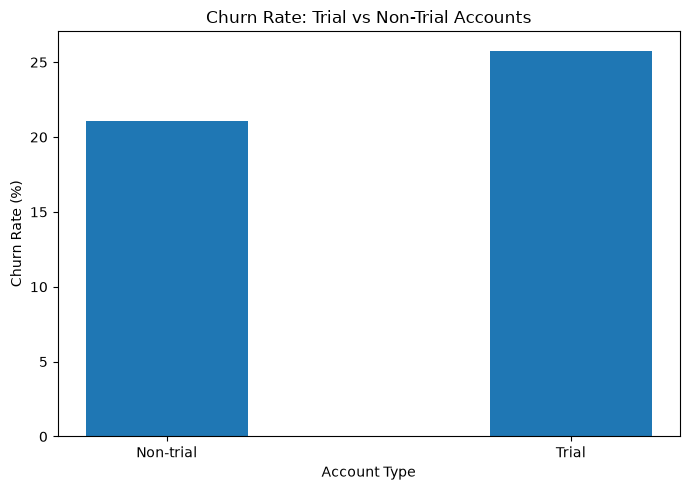

In [32]:
trial_churn_labels = trial_churn.copy()

trial_churn_labels["account_type"] = trial_churn_labels["is_trial"].map({
    False: "Non-trial",
    True: "Trial"
})

plt.figure(figsize=(7, 5))

plt.bar(
    trial_churn_labels["account_type"],
    trial_churn_labels["churn_rate_pct"],
    width=0.4
)

plt.title("Churn Rate: Trial vs Non-Trial Accounts")
plt.xlabel("Account Type")
plt.ylabel("Churn Rate (%)")

plt.tight_layout()
plt.show()

6. Which customer segments are worth investigating for retention?

In [31]:
churn_by_industry = accounts.groupby("industry").agg(
    account_count=("account_id", "count"),
    churned_accounts=("churn_flag", "sum")
).reset_index()

churn_by_industry["churn_rate_pct"] = (
    churn_by_industry["churned_accounts"]
    / churn_by_industry["account_count"]
    * 100
)

churn_by_industry = churn_by_industry.sort_values(
    by="churn_rate_pct",
    ascending=False
)

display(churn_by_industry.round(2))

,industry,account_count,churned_accounts,churn_rate_pct
1,DevTools,113,35,30.97
3,FinTech,112,25,22.32
4,HealthTech,96,21,21.88
2,EdTech,79,13,16.46
0,Cybersecurity,100,16,16.00


Analyze customers by referral source

In [23]:
referral_analysis = accounts.groupby("referral_source").agg(
    account_count=("account_id", "count"),
    churned_accounts=("churn_flag", "sum")
).reset_index()

referral_analysis["customer_share_pct"] = (
    referral_analysis["account_count"]
    / len(accounts)
    * 100
)

referral_analysis["churn_rate_pct"] = (
    referral_analysis["churned_accounts"]
    / referral_analysis["account_count"]
    * 100
)

referral_analysis = referral_analysis.sort_values(
    by="account_count",
    ascending=False
)

display(referral_analysis.round(2))

,referral_source,account_count,churned_accounts,customer_share_pct,churn_rate_pct
2,organic,114,20,22.8,17.54
3,other,103,25,20.6,24.27
0,ads,98,23,19.6,23.47
1,event,96,29,19.2,30.21
4,partner,89,13,17.8,14.61


Visualize churn rates by referral source

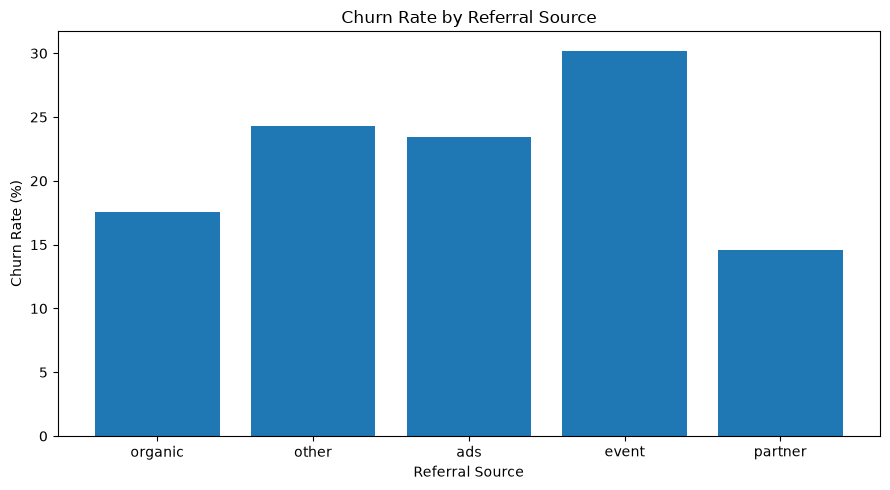

In [24]:
plt.figure(figsize=(9, 5))

plt.bar(
    referral_analysis["referral_source"],
    referral_analysis["churn_rate_pct"]
)

plt.title("Churn Rate by Referral Source")
plt.xlabel("Referral Source")
plt.ylabel("Churn Rate (%)")

plt.tight_layout()
plt.show()

Analyze customer size across subscription plans

In [25]:
plan_size = accounts.groupby("plan_tier").agg(
    account_count=("account_id", "count"),
    average_seats=("seats", "mean"),
    median_seats=("seats", "median"),
    total_seats=("seats", "sum")
).reset_index()

plan_size = plan_size.sort_values(
    by="average_seats",
    ascending=False
)

display(plan_size.round(2))

,plan_tier,account_count,average_seats,median_seats,total_seats
0,Basic,168,22.01,15.0,3697
2,Pro,178,19.95,16.0,3551
1,Enterprise,154,19.69,13.0,3032


Visualize average seats by subscription plan

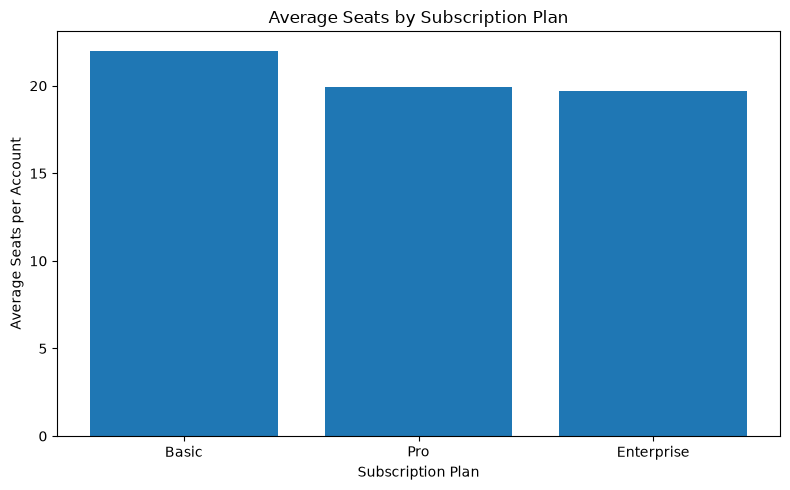

In [26]:
plt.figure(figsize=(8, 5))

plt.bar(
    plan_size["plan_tier"],
    plan_size["average_seats"]
)

plt.title("Average Seats by Subscription Plan")
plt.xlabel("Subscription Plan")
plt.ylabel("Average Seats per Account")

plt.tight_layout()
plt.show()

Which subscription plans are popular in different countries?

In [33]:
country_plan = pd.crosstab(
    accounts["country"],
    accounts["plan_tier"]
)

display(country_plan)

plan_tier,Basic,Enterprise,Pro
country,,,
AU,10,8,14
CA,6,8,9
DE,6,12,7
FR,6,9,7
IN,22,13,14
UK,23,18,17
US,95,86,110


## Customer Segmentation Analysis Conclusion

The customer segmentation analysis examined customer distribution across industries, countries, subscription plans, account sizes, trial status, and referral sources.

The analysis found that the United States contributed the largest share of accounts, while Pro was the most common subscription plan. EdTech had the highest average seats per account, and FinTech had the highest total seats. Trial accounts, DevTools customers, and event-referred accounts showed comparatively higher churn rates in their respective comparisons.

These findings highlight the importance of understanding customer characteristics and identifying segments that may need further investigation to improve retention. However, the observed differences do not establish the causes of churn, and account distribution alone does not indicate profitability.

See `docs/customer_segmentation_report.md` for the detailed findings and business recommendations.
